# Mario AI Challenge: notebook de experimentación (PPO)

**Estudiante:** Jonathan Alberto Salinas Sanchez · **Materia:** Inteligencia Artificial · **Repositorio:** `Kenauh/mario-ai-ppo`

En este notebook documento cómo desarrollé un agente que juega el Mundo 1-1 de Super Mario Bros. con aprendizaje por refuerzo (PPO), qué probé y qué resultados obtuve. **No vuelve a entrenar:** lee los CSV que guardé en `results/` y reproduce mis tablas y gráficas. Las dos celdas que necesitan el emulador (un entrenamiento corto y jugar un episodio con el agente exportado) están protegidas: si no hay emulador, explican cómo ejecutarlas en mi entorno local.

| Parte pedida | Dónde |
|---|---|
| 1. Representación del problema | Sección 1 |
| 2. Estrategia seleccionada | Sección 2 |
| 3. Configuración inicial | Sección 3 |
| 4. Procedimiento de entrenamiento | Sección 4 |
| 5. Segunda configuración | Sección 5 |
| 6. Resultados de ambas / 7. Gráficas y tablas comparativas | Secciones 6 y 7 |
| 8. Análisis de errores | Sección 8 |
| 9. Selección del agente final | Secciones 9 y 10 |

In [ ]:
# Celda 0: entorno y localizacion de los datos
import json, math, os, re, subprocess, sys, zipfile
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})


def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "results" / "eval").exists():
            return p
    return None


ROOT = find_root()
if ROOT is None and "google.colab" in sys.modules:
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    r = subprocess.run(["git", "clone", "-q", "https://github.com/Kenauh/mario-ai-ppo.git", "/content/mario-ai-ppo"],
                       capture_output=True, text=True, env=env)
    if r.returncode == 0:
        ROOT = Path("/content/mario-ai-ppo")
    else:
        from google.colab import files
        print("No pude clonar el repositorio (probablemente es privado). Sube results.zip (la carpeta results/ comprimida).")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content/repo")
        ROOT = Path("/content/repo")
if ROOT is None:
    raise FileNotFoundError("No encuentro la carpeta results/. Abre el notebook dentro del repositorio.")
os.chdir(ROOT)
RES = ROOT / "results"
print("Repositorio:", ROOT)
print("Python", sys.version.split()[0], "|", " | ".join(f"{p} {metadata.version(p)}" for p in ["numpy", "pandas", "matplotlib"]))

Repositorio: /content/mario-ai-ppo
Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0


In [ ]:
# Celda 1: funciones auxiliares y carga de las dos corridas
X_FLAG = 3161   # x de la bandera, medida en los episodios con flag_get=1


def wilson(k, n, z=1.96):
    # intervalo de confianza de Wilson al 95 % para una proporcion
    if n == 0:
        return float("nan"), float("nan")
    p, d = k / n, 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def load_run(folder):
    d = RES / folder
    out = {n: pd.read_csv(d / f"{n}.csv") for n in ["episodes", "eval", "progress", "train_stats"]}
    out["best"] = json.loads((d / "best_score.json").read_text())
    out["info"] = [json.loads(p.read_text()) for p in sorted(d.glob("run_info_*.json"))]
    return out


RUNS = {"cfg1 (escala 1)": load_run("cfg1_base"), "cfg2 (escala 0.02)": load_run("cfg2_reward_scale_5M")}
COLORS = {"cfg1 (escala 1)": "tab:red", "cfg2 (escala 0.02)": "tab:blue"}
try:
    BASE_MEAN = float(pd.read_csv(RES / "baseline_random.csv")["max_x"].mean())
except Exception:
    BASE_MEAN = None


def windows(ep, step=100_000):
    # resumen por ventanas de 100 000 pasos de entrenamiento
    e = ep.assign(v=((ep["timesteps"] - 1) // step + 1) * step)
    g = e.groupby("v")
    w = pd.DataFrame({"n": g.size(), "max_x_media": g["max_x"].mean(), "pct_bandera": g["flag_get"].mean() * 100,
                      "pct_limite": g["cause"].apply(lambda s: (s == "limite_fotogramas").mean() * 100)})
    return w[w["n"] >= 0.2 * w["n"].median()]   # descarta ventanas casi vacias (p. ej. el resto del ultimo rollout)


def train_hours(pr):
    # elapsed_s se reinicia en cada segmento (reanudacion): se suman los finales de cada segmento
    e = pr["elapsed_s"].to_numpy()
    ends = [e[i] for i in range(len(e) - 1) if e[i + 1] < e[i]] + [e[-1]]
    return sum(ends) / 3600, len(ends)


def summarize_eval(path):
    d = pd.read_csv(path)
    n, k = len(d), int(d["flag"].sum())
    lo, hi = wilson(k, n)
    col = "frames_info" if "frames_info" in d.columns else "frames"   # frames_info = conteo real de fotogramas
    fr = d.loc[d["flag"] == 1, col]
    m = re.search(r"_n(\d+)\.csv$", Path(path).name)
    return {"archivo": Path(path).name, "modo": d["mode"].iloc[0], "noop_max": int(m.group(1)) if m else None, "n": n,
            "banderas": k, "tasa_%": round(100 * k / n, 1), "IC95_%": f"{100 * lo:.1f} a {100 * hi:.1f}",
            "progreso": round(d["max_x"].mean() / X_FLAG, 3),
            "mediana_frames_exito": (float(fr.median()) if len(fr) else None),
            "fallos": dict(d.loc[d["flag"] == 0, "cause"].value_counts())}


def mcnemar(a_csv, b_csv):
    # comparacion pareada por semilla (prueba exacta de McNemar)
    a = pd.read_csv(RES / "eval" / a_csv).set_index("seed")["flag"]
    b = pd.read_csv(RES / "eval" / b_csv).set_index("seed")["flag"]
    only_b, only_a = int(((b == 1) & (a == 0)).sum()), int(((a == 1) & (b == 0)).sum())
    n = only_a + only_b
    p = min(1.0, 2 * sum(math.comb(n, i) for i in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
    return {"solo_el_segundo": only_b, "solo_el_primero": only_a, "p_exacta": round(p, 4)}


def zone_table(ep, zone=100, xflag=X_FLAG):
    # cadena absorbente por zonas de x: q_muerte = P(morir en la zona | llego a ella), p_sigue = P(pasar a la siguiente)
    z = (ep["max_x"] // zone).astype(int)
    rows = []
    for k in range(xflag // zone + 1):
        reach = int((z >= k).sum())
        if reach == 0:
            break
        end = int((z == k).sum())
        m = int(((z == k) & (ep["cause"] == "muerte")).sum())
        s = int(((z == k) & (ep["cause"] == "limite_fotogramas")).sum())
        b = int(((z == k) & (ep["flag_get"] == 1)).sum())
        rows.append(dict(zona=k * zone, llegan=reach, muerte=m, atasco=s, bandera=b, q_muerte=m / reach, p_sigue=(reach - end) / reach))
    return pd.DataFrame(rows)


print({k: len(v["episodes"]) for k, v in RUNS.items()}, "episodios cargados | azar (media de max_x):", BASE_MEAN)

{'cfg1 (escala 1)': 70955, 'cfg2 (escala 0.02)': 24778} episodios cargados | azar (media de max_x): 861.48


## 1. Representación del problema

Lo que tenía que resolver era que un agente llegara por sí solo a la bandera del Mundo 1-1 viendo únicamente la imagen del juego. No me propuse superar al agente del docente: me enfoqué en diseñar bien la solución, implementarla y analizar sus resultados.

| # | Punto | Cómo lo definí |
|---|---|---|
| 1 | Objetivo | Llegar a la bandera (x = 3161, medida) sin intervención humana; como objetivo secundario, hacerlo en pocos fotogramas |
| 2 | Información observable | La imagen RGB de 240×256×3. Mi política **nunca** recibe `info` (x, bandera, vidas): esos datos solo los uso para métricas y para la recompensa |
| 3 | Estado | Pila de las últimas 4 imágenes en gris de 84×84 (4×84×84, uint8), una por decisión |
| 4 | Acciones | 7 acciones discretas: NOOP, right, right+A, right+B, right+A+B, A, left. Cada decisión se mantiene 4 fotogramas |
| 5 | Obstáculos y riesgos | Goombas, Koopas, tuberías, huecos y escaleras (las zonas peligrosas las mido en la sección 8) |
| 6 | Éxito y fracaso | Éxito: tocar la bandera. Fracaso: morir o agotar el límite de fotogramas (8000) |
| 7 | Selección de acciones | La red da una probabilidad por botón π(a∣s); elijo la más probable (determinista) o muestreo (estocástico) |
| 8 | Limitaciones | Las resumo en la sección 11 |

**Cómo lo modelé.** Primero comprobé que el emulador es determinista (dos corridas iguales dieron exactamente lo mismo), así que el juego completo es un proceso de Markov. Mi agente, en cambio, solo ve imágenes, por lo que en realidad el problema es parcialmente observable (POMDP). Lo aproximo como un MDP sobre la pila de 4 fotogramas: (S, A, P, R, γ) con γ = 0.99 y P determinista. Apilar fotogramas me da lo que una sola imagen no tiene (hacia dónde se mueve Mario), pero no recupera todo: por ejemplo, no puedo ver si el botón A sigue pulsado.

**La cadena de Markov.** Modelé mi estrategia como cadena de Markov. Cuando fijo la política π, el agente ya no elige y el sistema es una cadena sobre los estados con transición P_π(s'∣s) = Σₐ π(a∣s)·P(s'∣s,a). Si el agente usa la acción más probable, la cadena es una sola trayectoria; si muestrea, la trayectoria se ramifica. Morir, tocar la bandera y agotar el límite de fotogramas son estados absorbentes, y un atasco (Mario quieto y el argmax repitiendo el botón) es un estado casi absorbente que no es terminal. En la sección 8 estimo además una cadena absorbente por zonas de x a partir de mis datos.

**Recompensa.** Leí el código del emulador: R = Δx + Δreloj − 25 si Mario muere. Lo comprobé con mis datos: en los episodios con bandera del piloto, la recompensa del episodio coincide con (x_final − 40) − (400 − reloj restante) en 5 de 6; en el sexto difiere en 6 puntos.

## 2. Estrategia seleccionada: PPO

Elegí **PPO (Proximal Policy Optimization)** con Stable-Baselines3 y la política `CnnPolicy`, usando solo píxeles como entrada. Mis razones: mis acciones son discretas y pocas (7); PPO es relativamente estable de entrenar; permite juntar experiencia de varios entornos en paralelo; es un método estándar en juegos de este tipo; y el profesor despues me comentó que suele dar muy buenos resultados.

Así lo entiendo: es un método actor-crítico *on-policy*. El actor es la política π(a∣s), la probabilidad de cada botón, y el crítico V(s) estima cuánto retorno espero desde un estado. En cada iteración mis 8 entornos juegan 128 pasos (1024 muestras), calculo qué tan buena fue cada acción respecto a lo esperado (la ventaja, con GAE y λ = 0.95) y actualizo la red durante 4 épocas con minilotes de 256. La clave de PPO es el recorte: la razón entre la política nueva y la vieja se limita a [0.9, 1.1] para que una actualización no cambie demasiado la política. Además sumo una bonificación de entropía (0.01) para que siga explorando.

**Decisión de portabilidad.** Decidí que el agente final se ejecute **sin SB3, Gymnasium ni NES-Py**: solo con PyTorch, NumPy y OpenCV, con la política exportada a un archivo `.pt`. Entreno con SB3, pero conservo el código de entrenamiento, los modelos originales y las configuraciones, y no sacrifiqué rendimiento ni reproducibilidad por esa decisión. En la sección 9 muestro que el agente portable da exactamente las mismas respuestas que SB3.

In [ ]:
# Celda 2: hiperparametros y configuracion (se leen de configs/; si no estan, se usan los valores del experimento)
FALLBACK_BASE = {"name": "cfg1_base", "seed": 0, "total_timesteps": 2000000, "n_envs": 8, "checkpoint_every": 100000,
                 "env": {"skip": 4, "max_frames": 8000, "size": 84, "n_stack": 4},
                 "ppo": {"learning_rate": 0.00025, "n_steps": 128, "batch_size": 256, "n_epochs": 4, "gamma": 0.99,
                          "gae_lambda": 0.95, "clip_range": 0.1, "ent_coef": 0.01, "vf_coef": 0.5, "max_grad_norm": 0.5},
                 "eval_every": 50000, "reward_scale": 1.0}


def read_cfg(name, fallback):
    p = ROOT / "configs" / name
    return json.loads(p.read_text()) if p.exists() else fallback


CFG1 = read_cfg("base.json", FALLBACK_BASE)
CFG2 = read_cfg("cfg2_reward_scale.json", {**FALLBACK_BASE, "name": "cfg2_reward_scale", "reward_scale": 0.02})
display(pd.Series(CFG1["ppo"], name="PPO (identico en las dos configuraciones)").to_frame())
print({k: v for k, v in CFG1.items() if k not in ("ppo", "env")}, CFG1["env"])

,PPO (identico en las dos configuraciones)
learning_rate,0.00025
n_steps,128.00000
batch_size,256.00000
n_epochs,4.00000
gamma,0.99000
gae_lambda,0.95000
clip_range,0.10000
ent_coef,0.01000
vf_coef,0.50000
max_grad_norm,0.50000


{'name': 'cfg1_base', 'seed': 0, 'total_timesteps': 2000000, 'n_envs': 8, 'checkpoint_every': 100000, 'eval_every': 50000, 'reward_scale': 1.0} {'skip': 4, 'max_frames': 8000, 'size': 84, 'n_stack': 4}


## 3. Configuración inicial (Config 1: recompensa sin escalar)

Mi configuración inicial (`configs/base.json`, nombre `cfg1_base`) usa la recompensa del entorno tal cual (`reward_scale = 1.0`) con los hiperparámetros de arriba. Los tomé como **punto de partida típico y no los optimicé**. Usé semilla 0 y 8 entornos en paralelo. El archivo dice 2 000 000 de pasos; después extendí la corrida a 5 000 000 con `--total-steps`.

Antes de entrenar medí desde dónde parto: una política aleatoria uniforme (50 episodios) llega en promedio a x ≈ 861 (mediana 875, p10 297, p90 1415, máximo 1796) y nunca a la bandera. Ese es el nivel que un agente entrenado debe superar.

## 4. Procedimiento de entrenamiento

1. **Entorno y velocidad.** Usé el emulador `nes-py` con wrappers propios (repetir la acción 4 fotogramas, pasar a gris 84×84 y apilar 4). Medí ≈ 180 decisiones por segundo con un entorno y ≈ 455 a 550 fps entrenando con 8.
2. **Diagnóstico antes de las corridas formales** (todo medido). Un checkpoint temprano jugando de forma determinista se quedaba en x = 40 con la acción A: es un punto fijo del argmax, no un error de exportación. Con recompensa sin escalar, el gradiente del crítico es de ≈ 3×10⁴ a 8×10⁴ veces el de la política en la red compartida (medición aproximada), y con escala 0.02 baja a ≈ 320. En pilotos de 300 000 pasos, la escala 1 fue errática y la 0.02 estable pero al nivel del azar.
3. **Corridas formales** con `scripts/train.py`: registro por episodio, evaluación determinista cada 50 000 pasos, checkpoints cada 100 000 y un `run_info` con comando, versiones, GPU y commit.
4. **Puerta de decisión a 1 M de pasos para la Config 2**, que fijé antes de ver datos: continuar si la media de `max_x` de los últimos 100 000 pasos era ≥ 1000 o si la evaluación determinista superaba 700. Aplicada después con los datos completos, la puerta decía «interrumpir» (955 y 594); la corrida no se interrumpió y despegó pasado 1.3 ,ahi empece a ver grandes avances conforme aumentaba.

La tabla siguiente sale de los `run_info` de cada segmento.

In [ ]:
# Celda 3: segmentos de entrenamiento (run_info) y recursos
rows = []
for name, r in RUNS.items():
    for i in r["info"]:
        rows.append({"config": name, "comando": " ".join(i.get("cmd", [])), "resume_from": i.get("resume_from"),
                     "commit": (i.get("git_commit") or "")[:7], "gpu": i.get("gpu")})
display(pd.DataFrame(rows))
for name, r in RUNS.items():
    h, segs = train_hours(r["progress"])
    print(f"{name}: {h:.2f} h de entrenamiento en {segs} segmento(s) | pasos finales: {int(r['progress']['timesteps'].iloc[-1]):,}")

,config,comando,resume_from,commit,gpu
0,cfg1 (escala 1),scripts/train.py --config configs/base.json --...,None,9598282,NVIDIA GeForce RTX 4070 Ti
1,cfg1 (escala 1),scripts/train.py --config configs/base.json --...,ckpt_2600000_steps.zip,546a440,NVIDIA GeForce RTX 4070 Ti
2,cfg2 (escala 0.02),scripts/train.py --config configs/cfg2_reward_...,None,f98d76c,NVIDIA GeForce RTX 4070 Ti
3,cfg2 (escala 0.02),scripts/train.py --config configs/cfg2_reward_...,ckpt_2000896_steps.zip,546a440,NVIDIA GeForce RTX 4070 Ti


cfg1 (escala 1): 2.66 h de entrenamiento en 2 segmento(s) | pasos finales: 5,000,256
cfg2 (escala 0.02): 2.83 h de entrenamiento en 2 segmento(s) | pasos finales: 5,000,192


In [ ]:
# Celda 4: entrenamiento CORTO (50 000 pasos). Necesita el entorno de entrenamiento (emulador + SB3).
RUN_SHORT_TRAINING = False   # cambia a True para lanzarlo, no recomendable aqui en colab pero lo agrego como añadido

if RUN_SHORT_TRAINING:
    cmd = [sys.executable, "scripts/train.py", "--config", "configs/base.json", "--name", "smoke_nb",
           "--total-steps", "50000", "--n-envs", "4"]
    print(" ".join(cmd))
    subprocess.run(cmd, check=False)
    p = ROOT / "runs" / "smoke_nb" / "progress.csv"
    if p.exists():
        display(pd.read_csv(p).tail(3))
else:
    print("Entrenamiento corto desactivado (RUN_SHORT_TRAINING = False).")
    print("Comando equivalente, desde la raiz del repositorio y con el entorno de entrenamiento activo:")
    print("  python scripts/train.py --config configs/base.json --name smoke_nb --total-steps 50000 --n-envs 4")

Entrenamiento corto desactivado (RUN_SHORT_TRAINING = False).
Comando equivalente, desde la raiz del repositorio y con el entorno de entrenamiento activo:
  python scripts/train.py --config configs/base.json --name smoke_nb --total-steps 50000 --n-envs 4


## 5. Segunda configuración (Config 2: recompensa escalada ×0.02)

Para mi segunda configuración cambié **una sola variable**: `reward_scale = 0.02`, y solo durante el entrenamiento (las métricas las calculo siempre con la recompensa sin escalar). Mantuve la misma semilla, los mismos pasos, los mismos entornos y el mismo PPO. Elegí esta variable, y no `ent_coef`, que era mi idea inicial, porque mis mediciones previas apuntaban a que la magnitud de la recompensa era lo que más desbalanceaba el entrenamiento.

**Mi hipótesis H1**, fijada antes de ver datos de cfg1: con `reward_scale = 1`, el gradiente del crítico domina el extractor de características compartido; por eso, a 2 M de pasos, cfg1 tendrá menos banderas que cfg2 en la última ventana. Métricas que fijé de antemano: tasa de bandera y media de `max_x` en (1.9 M, 2.0 M], y los pasos hasta la primera ventana con media ≥ 1000. Si cfg1 igualaba o superaba a cfg2, H1 quedaba refutada.

In [ ]:
# Celda 5: diferencias entre las dos configuraciones
def flat(d, pre=""):
    out = {}
    for k, v in d.items():
        out.update(flat(v, pre + k + ".") if isinstance(v, dict) else {pre + k: v})
    return out


f1, f2 = flat(CFG1), flat(CFG2)
diff = {k: (f1.get(k), f2.get(k)) for k in sorted(set(f1) | set(f2)) if f1.get(k) != f2.get(k)}
display(pd.DataFrame(diff, index=["cfg1", "cfg2"]).T)

,cfg1,cfg2
name,cfg1_base,cfg2_reward_scale
reward_scale,1.0,0.02


## 6. Resultados de ambas configuraciones (métricas de entrenamiento)

Estas curvas salen de los episodios que terminaron durante el entrenamiento, que son estocásticos, y tengo una sola semilla por configuración. La evaluación con condiciones controladas está en la sección 7.

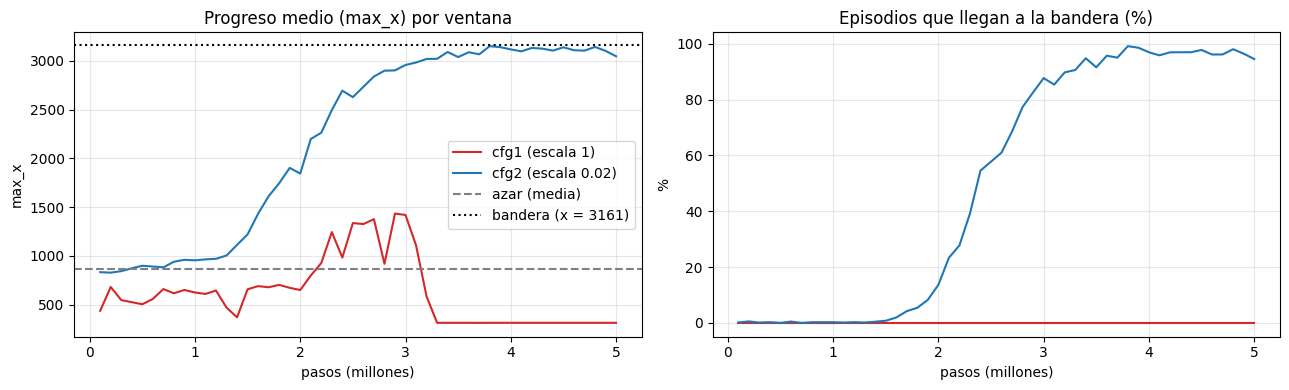

In [ ]:
# Celda 6: curvas de aprendizaje por ventanas de 100 000 pasos
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, r in RUNS.items():
    w = windows(r["episodes"])
    ax[0].plot(w.index / 1e6, w["max_x_media"], label=name, color=COLORS[name])
    ax[1].plot(w.index / 1e6, w["pct_bandera"], label=name, color=COLORS[name])
if BASE_MEAN:
    ax[0].axhline(BASE_MEAN, ls="--", color="gray", label="azar (media)")
ax[0].axhline(X_FLAG, ls=":", color="black", label="bandera (x = 3161)")
ax[0].set(title="Progreso medio (max_x) por ventana", xlabel="pasos (millones)", ylabel="max_x")
ax[1].set(title="Episodios que llegan a la bandera (%)", xlabel="pasos (millones)", ylabel="%")
ax[0].legend()
plt.tight_layout()
plt.show()

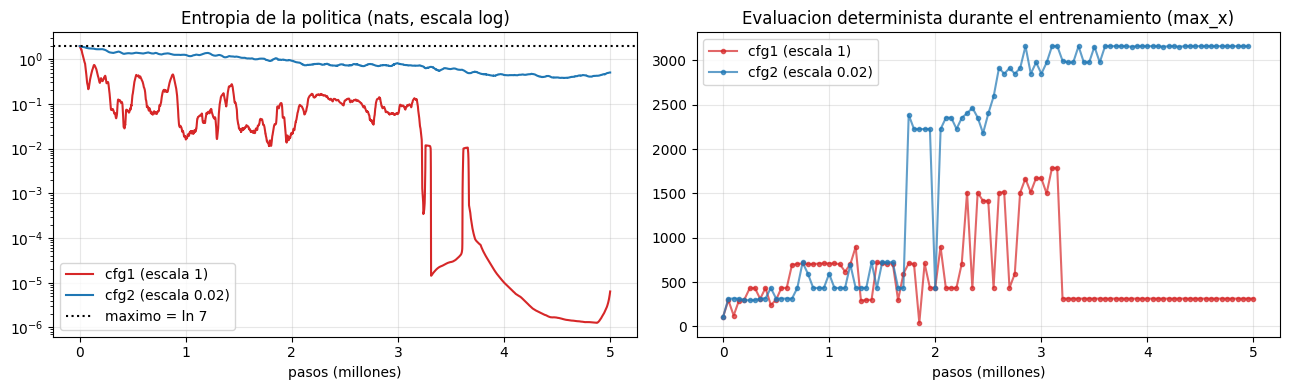

In [ ]:
# Celda 7: entropia de la politica y evaluacion determinista durante el entrenamiento
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, r in RUNS.items():
    st, ev = r["train_stats"], r["eval"]
    ent = (-st["entropy_loss"]).rolling(50, min_periods=1).mean()
    ax[0].semilogy(st["total_timesteps"] / 1e6, np.clip(ent, 1e-7, None), label=name, color=COLORS[name])
    ax[1].plot(ev["timesteps"] / 1e6, ev["det_max_x"], ".-", label=name, color=COLORS[name], alpha=0.7)
ax[0].axhline(np.log(7), ls=":", color="black", label="maximo = ln 7")
ax[0].set(title="Entropia de la politica (nats, escala log)", xlabel="pasos (millones)")
ax[1].set(title="Evaluacion determinista durante el entrenamiento (max_x)", xlabel="pasos (millones)")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# Celda 8: comparacion oficial de H1 (ventana (1.9M, 2.0M]) y ventana final (4.9M, 5.0M]
def window_stats(ep, a, b):
    w = ep[(ep["timesteps"] > a) & (ep["timesteps"] <= b)]
    return {"episodios": len(w), "banderas": int(w["flag_get"].sum()), "% bandera": round(w["flag_get"].mean() * 100, 1),
            "max_x medio": round(w["max_x"].mean())}


rows = []
for name, r in RUNS.items():
    for lab, a, b in [("(1.9M, 2.0M] <- H1", 1_900_000, 2_000_000), ("(4.9M, 5.0M]", 4_900_000, 5_000_000)]:
        rows.append({"config": name, "ventana": lab, **window_stats(r["episodes"], a, b)})
display(pd.DataFrame(rows))
for name, r in RUNS.items():
    w = windows(r["episodes"])
    hit = w[w["max_x_media"] >= 1000]
    print(f"{name}: primera ventana con media de max_x >= 1000:", f"({hit.index[0] - 100_000:,}, {hit.index[0]:,}]" if len(hit) else "ninguna")
    print("   mejor checkpoint segun la evaluacion determinista (best_score = [bandera, max_x, -fotogramas]):", r["best"])

,config,ventana,episodios,banderas,% bandera,max_x medio
0,cfg1 (escala 1),"(1.9M, 2.0M] <- H1",177,0,0.0,650
1,cfg1 (escala 1),"(4.9M, 5.0M]",3333,0,0.0,314
2,cfg2 (escala 0.02),"(1.9M, 2.0M] <- H1",462,63,13.6,1844
3,cfg2 (escala 0.02),"(4.9M, 5.0M]",368,348,94.6,3046


cfg1 (escala 1): primera ventana con media de max_x >= 1000: (2,200,000, 2,300,000]
   mejor checkpoint segun la evaluacion determinista (best_score = [bandera, max_x, -fotogramas]): [0, 1789, -950]
cfg2 (escala 0.02): primera ventana con media de max_x >= 1000: (1,200,000, 1,300,000]
   mejor checkpoint segun la evaluacion determinista (best_score = [bandera, max_x, -fotogramas]): [1, 3161, -1080]


**Lo que veo (valores medidos en mis corridas).** A 2 M, cfg1 no logra ninguna bandera en su última ventana y cfg2 logra 13.6 %. A 5 M, cfg1 muere en x ≈ 314 en todos los episodios y cfg2 llega a la bandera en ≈ 95 %. La entropía de cfg1 cae a ≈ 0.07 nats ya a 258 000 pasos (la de cfg2 es 1.34): su política deja de explorar.

**Cautela.** Es una semilla por configuración, y esta comparación solo varía la escala. Apoya la predicción de H1, pero no aísla el mecanismo (que el crítico domine); para eso necesitaría otra corrida, por ejemplo separando actor y crítico.

## 7. Evaluación estandarizada y comparación

Definí el protocolo **antes** de ver los resultados, con los checkpoints de 2 M y de 5 M de cada configuración (los elegí por número de pasos, no por su desempeño, para no meter sesgo de selección):

- **P1** (inicio estándar): 100 episodios estocásticos (semillas 0 a 99) y 1 determinista.
- **P2** (robustez): antes de jugar, *k* decisiones NOOP con *k* de 0 a 8 (0 a 32 fotogramas); 100 episodios estocásticos y 9 deterministas.
- Uso intervalos de Wilson al 95 %. El progreso es x máxima / 3161. Los fotogramas de éxito son el conteo real (`frames_info`); en P2 incluyen los 4k fotogramas de espera.

In [ ]:
# Celda 9: tabla de la evaluacion estandarizada
std = sorted((RES / "eval").glob("cfg[12]_[25]M_*_n[08].csv"))
T = pd.DataFrame([summarize_eval(p) for p in std])
T.insert(0, "protocolo", T["noop_max"].map({0: "P1", 8: "P2"}))
T.insert(0, "checkpoint", T["archivo"].str.extract(r"(cfg\d_\dM)")[0])
display(T[["checkpoint", "protocolo", "modo", "n", "banderas", "tasa_%", "IC95_%", "progreso", "mediana_frames_exito", "fallos"]])

,checkpoint,protocolo,modo,n,banderas,tasa_%,IC95_%,progreso,mediana_frames_exito,fallos
0,cfg1_2M,P1,det,1,0,0.0,0.0 a 79.3,0.138,NaN,{'limite_fotogramas': 1}
1,cfg1_2M,P2,det,9,0,0.0,0.0 a 29.9,0.138,NaN,{'limite_fotogramas': 9}
2,cfg1_2M,P1,stoch,100,0,0.0,0.0 a 3.7,0.210,NaN,"{'muerte': 69, 'limite_fotogramas': 31}"
3,cfg1_2M,P2,stoch,100,0,0.0,0.0 a 3.7,0.212,NaN,"{'muerte': 69, 'limite_fotogramas': 31}"
4,cfg1_5M,P1,det,1,0,0.0,0.0 a 79.3,0.099,NaN,{'muerte': 1}
5,cfg1_5M,P2,det,9,0,0.0,0.0 a 29.9,0.099,NaN,{'muerte': 9}
6,cfg1_5M,P1,stoch,100,0,0.0,0.0 a 3.7,0.099,NaN,{'muerte': 100}
7,cfg1_5M,P2,stoch,100,0,0.0,0.0 a 3.7,0.099,NaN,{'muerte': 100}
8,cfg2_2M,P1,det,1,0,0.0,0.0 a 79.3,0.137,NaN,{'limite_fotogramas': 1}
9,cfg2_2M,P2,det,9,0,0.0,0.0 a 29.9,0.280,NaN,{'limite_fotogramas': 9}


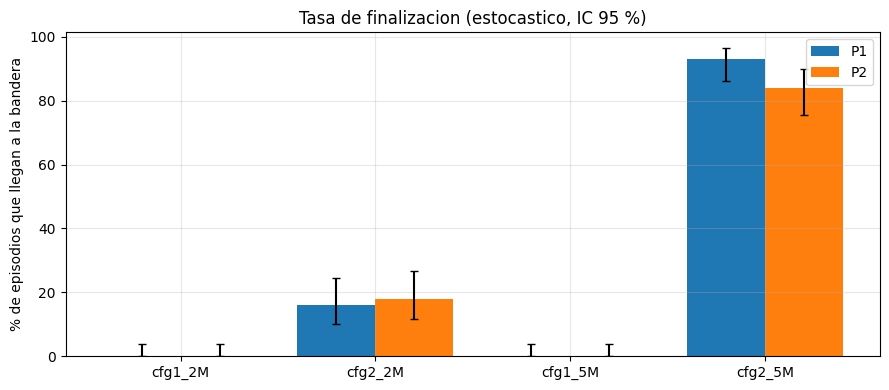

In [ ]:
# Celda 10: tasa de finalizacion (estocastico) con intervalos de confianza
S = T[T["modo"] == "stoch"].reset_index(drop=True)
labels = ["cfg1_2M", "cfg2_2M", "cfg1_5M", "cfg2_5M"]
fig, ax = plt.subplots(figsize=(9, 4))
for proto, off in [("P1", -0.2), ("P2", 0.2)]:
    sub = S[S["protocolo"] == proto].set_index("checkpoint").reindex(labels)
    ks, ns = sub["banderas"].astype(int).to_numpy(), sub["n"].astype(int).to_numpy()
    lo = np.array([wilson(b, n)[0] * 100 for b, n in zip(ks, ns)])
    hi = np.array([wilson(b, n)[1] * 100 for b, n in zip(ks, ns)])
    y = sub["tasa_%"].to_numpy(dtype=float)
    ax.bar(np.arange(4) + off, y, 0.4, yerr=[y - lo, hi - y], capsize=3, label=proto)
ax.set_xticks(range(4))
ax.set_xticklabels(labels)
ax.set(ylabel="% de episodios que llegan a la bandera", title="Tasa de finalizacion (estocastico, IC 95 %)")
ax.legend()
plt.tight_layout()
plt.show()

**Lo que veo.** A 2 M, cfg1 hace 0 de 100 (IC de 0 a 3.7 %) y cfg2 16 de 100 (10.1 a 24.4 %); los intervalos no se solapan. A 5 M son 0 de 100 contra 93 de 100. En cfg1, ≈ 31 % de los episodios a 2 M terminan atascados por el límite de fotogramas; en cfg2, ninguno. A 2 M, el determinista de cfg2 se atasca siempre mientras el estocástico llega a la meta en 16 a 18 %.

Algo que no esperaba: cfg2 a 5 M baja de 93 % en P1 a 84 % en P2. Con las mismas semillas, la comparación pareada indica que el efecto es detectable (p ≈ 0.02), y en la sección 8 explico dónde se concentra.

## 8. Análisis de errores

Para ver dónde falla mi agente construí una **cadena absorbente por zonas**: divido el nivel en zonas de 100 píxeles de x y, para cada zona, estimo `q_muerte` (la probabilidad de morir en la zona dado que se llegó a ella) y `p_sigue` (la probabilidad de pasar a la siguiente). El producto de los `p_sigue`, por la probabilidad de bandera en la última zona, reproduce la tasa de bandera por construcción; lo uso como comprobación de consistencia y no como un hallazgo. Su límite: la probabilidad de pasar una zona depende de cómo llegué a ella, así que es un resumen descriptivo y no un modelo exacto, y cada ventana mezcla checkpoints que cambian durante el entrenamiento.

== cfg2, pasos (1.5M, 2.0M]: 2394 episodios, tasa de bandera 0.063, producto de la cadena 0.063


,zona,llegan,muerte,atasco,bandera,q_muerte,p_sigue
17,1700,1289,437,0,0,0.339,0.661
15,1500,1646,266,0,0,0.162,0.838
24,2400,410,211,0,0,0.515,0.485
20,2000,624,210,0,0,0.337,0.663
6,600,2355,184,0,0,0.078,0.922


== cfg1, pasos (0, 2.0M]: 5430 episodios, tasa de bandera 0.000, producto de la cadena 0.000


,zona,llegan,muerte,atasco,bandera,q_muerte,p_sigue
7,700,2973,2028,560,0,0.682,0.129
2,200,5407,939,0,0,0.174,0.826
3,300,4468,842,0,0,0.188,0.812
6,600,3540,565,2,0,0.160,0.840
8,800,385,232,78,0,0.603,0.195


== cfg2, pasos (4M, 5M]: 3658 episodios, tasa de bandera 0.966, producto de la cadena 0.966


,zona,llegan,muerte,atasco,bandera,q_muerte,p_sigue
6,600,3651,24,0,0,0.007,0.993
27,2700,3556,22,0,0,0.006,0.994
17,1700,3603,19,0,0,0.005,0.995
24,2400,3574,18,0,0,0.005,0.995
8,800,3625,11,0,0,0.003,0.997


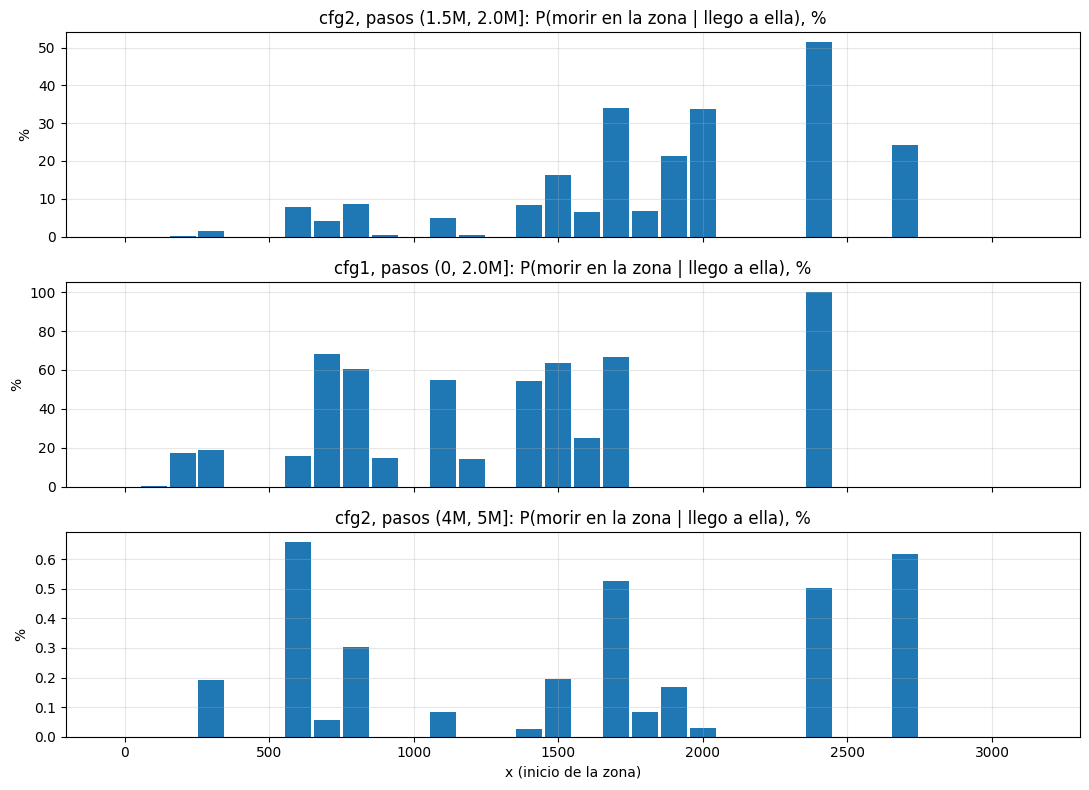

In [ ]:
# Celda 11: zonas de muerte (cadena empirica)
WINS = [("cfg2, pasos (1.5M, 2.0M]", "cfg2 (escala 0.02)", 1_500_000, 2_000_896),
        ("cfg1, pasos (0, 2.0M]", "cfg1 (escala 1)", 0, 2_000_000),
        ("cfg2, pasos (4M, 5M]", "cfg2 (escala 0.02)", 4_000_000, 10 ** 12)]
fig, axs = plt.subplots(len(WINS), 1, figsize=(11, 8), sharex=True)
for ax, (title, run, a, b) in zip(axs, WINS):
    ep = RUNS[run]["episodes"]
    ep = ep[(ep["timesteps"] > a) & (ep["timesteps"] <= b)]
    t = zone_table(ep)
    ax.bar(t["zona"], t["q_muerte"] * 100, width=90)
    ax.set(title=f"{title}: P(morir en la zona | llego a ella), %", ylabel="%")
    prod = t["p_sigue"].iloc[:-1].prod() * (t["bandera"].iloc[-1] / t["llegan"].iloc[-1])
    print(f"== {title}: {len(ep)} episodios, tasa de bandera {ep['flag_get'].mean():.3f}, producto de la cadena {prod:.3f}")
    display(t.sort_values("muerte", ascending=False).head(5).round(3))
axs[-1].set_xlabel("x (inicio de la zona)")
plt.tight_layout()
plt.show()

Fallos de cfg2 a 5 M por zona de x (bins de 50 px):


protocolo,P1,P2
x_aprox,,
300,2,9
650,1,1
1750,1,0
1950,0,1
2450,3,2
2750,0,3


P1 contra P2 (mismas semillas): 11 episodios llegan en P1 y fallan en P2; 2 llegan en P2 y fallan en P1; p exacta (McNemar) = 0.0225
P2 (cfg2 a 5 M): fallos por retraso inicial k


k_noop,0,1,2,3,4,5,6,7,8
episodios,12,11,11,11,11,11,11,11,11
banderas,12,11,9,11,10,8,10,9,4
fallos,0,0,2,0,1,3,1,2,7


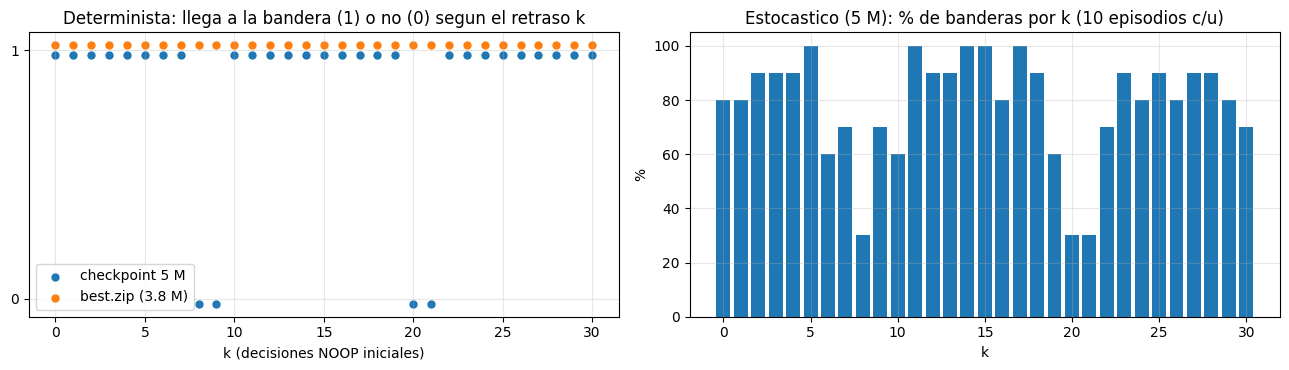

In [ ]:
# Celda 12: fallos del checkpoint de 5 M (P1 y P2) y barrido del retraso inicial
fails = pd.concat([pd.read_csv(RES / "eval" / f).assign(protocolo=p)
                   for f, p in [("cfg2_5M_stoch_n0.csv", "P1"), ("cfg2_5M_stoch_n8.csv", "P2")]], ignore_index=True)
fails = fails[fails["flag"] == 0].copy()
fails["x_aprox"] = (fails["max_x"] // 50) * 50
print("Fallos de cfg2 a 5 M por zona de x (bins de 50 px):")
display(pd.crosstab(fails["x_aprox"], fails["protocolo"]))

m = mcnemar("cfg2_5M_stoch_n0.csv", "cfg2_5M_stoch_n8.csv")
print(f"P1 contra P2 (mismas semillas): {m['solo_el_primero']} episodios llegan en P1 y fallan en P2; "
      f"{m['solo_el_segundo']} llegan en P2 y fallan en P1; p exacta (McNemar) = {m['p_exacta']}")
p2 = pd.read_csv(RES / "eval" / "cfg2_5M_stoch_n8.csv")
print("P2 (cfg2 a 5 M): fallos por retraso inicial k")
display(p2.groupby("k_noop")["flag"].agg(episodios="size", banderas="sum").assign(fallos=lambda d: d["episodios"] - d["banderas"]).T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (lab, f) in enumerate([("checkpoint 5 M", "cfg2_5M_det_n30.csv"), ("best.zip (3.8 M)", "test_cfg2_best_det_n30.csv")]):
    d = pd.read_csv(RES / "eval" / f).sort_values("k_noop")
    ax[0].scatter(d["k_noop"], d["flag"] + 0.04 * (i - 0.5), label=lab, s=25)
ax[0].set(title="Determinista: llega a la bandera (1) o no (0) segun el retraso k", xlabel="k (decisiones NOOP iniciales)", yticks=[0, 1])
ax[0].legend()
s = pd.read_csv(RES / "eval" / "cfg2_5M_stoch_n30.csv").groupby("k_noop")["flag"].mean() * 100
ax[1].bar(s.index, s.values)
ax[1].set(title="Estocastico (5 M): % de banderas por k (10 episodios c/u)", xlabel="k", ylabel="%")
plt.tight_layout()
plt.show()

**Lo que veo (medido).** En cfg2 a 5 M, los fallos se concentran en el **primer obstáculo** (x ≈ 315): 2 de 7 en P1 y 9 de 16 en P2, con muerte a los 108 a 140 fotogramas. En los videos que grabé con retraso k = 8, el checkpoint de 5 M salta antes y cae de frente sobre el primer Goomba; `best.zip` salta más tarde y llega a la bandera. El determinista de 5 M falla en k = 8, 9, 20 y 21 (27 de 31 trayectorias) y el estocástico tiene sus tasas más bajas justo ahí (3 de 10). Mi hipótesis, que no he probado, es que el salto de ese checkpoint está sincronizado con la ruta sin espera y un retraso lo desfasa del enemigo.

Los otros fallos coinciden con lugares que ya había visto: el par de Goombas (x ≈ 1791), el hueco entre escaleras (x ≈ 2469) y una zona antes de llegar al final (x ≈ 2757). Además, a 2 M vi tres atascos deterministas en video, con la imagen casi congelada: en x = 40, en la primera tubería (x = 434) y en el valle entre escaleras (x = 2226).

## 9. Selección del agente final

Fijé esta regla **antes** de ver los resultados. Evalúo candidatos tardíos de cfg2 en P2 estocástico con las semillas 0 a 99 (mi conjunto de *selección*). Un candidato reemplaza al de 5 M solo si logra al menos 87 banderas de 100; si la diferencia entre candidatos es de 2 puntos o menos, gana el de menor mediana de fotogramas. El elegido lo reporto con otras semillas (1000 a 1099, mi conjunto de *prueba*) y con un barrido determinista de 31 retrasos iniciales.

In [ ]:
# Celda 13: seleccion de checkpoint (semillas de seleccion 0-99, P2 estocastico)
SEL = [("3.0M", "sel_cfg2_3000k_stoch_n8.csv"), ("3.8M (best.zip)", "sel_cfg2_best_stoch_n8.csv"),
       ("4.0M", "sel_cfg2_4000k_stoch_n8.csv"), ("4.5M", "sel_cfg2_4500k_stoch_n8.csv"),
       ("5.0M (final)", "cfg2_5M_stoch_n8.csv")]
rows = []
for lab, f in SEL:
    s = summarize_eval(RES / "eval" / f)
    rows.append({"candidato": lab, **{k: s[k] for k in ["n", "banderas", "tasa_%", "IC95_%", "progreso", "mediana_frames_exito"]}})
display(pd.DataFrame(rows))
for lab, f in [SEL[1], SEL[3]]:
    print(f"{lab} contra el de 5 M (pareado por semilla):", mcnemar("cfg2_5M_stoch_n8.csv", f))

,candidato,n,banderas,tasa_%,IC95_%,progreso,mediana_frames_exito
0,3.0M,100,60,60.0,50.2 a 69.1,0.798,1269.0
1,3.8M (best.zip),100,96,96.0,90.2 a 98.4,0.972,1105.5
2,4.0M,100,83,83.0,74.5 a 89.1,0.932,1115.0
3,4.5M,100,95,95.0,88.8 a 97.8,0.981,1110.0
4,5.0M (final),100,84,84.0,75.6 a 89.9,0.899,1108.0


3.8M (best.zip) contra el de 5 M (pareado por semilla): {'solo_el_segundo': 16, 'solo_el_primero': 4, 'p_exacta': 0.0118}
4.5M contra el de 5 M (pareado por semilla): {'solo_el_segundo': 16, 'solo_el_primero': 5, 'p_exacta': 0.0266}


In [ ]:
# Celda 14: prueba del agente elegido (semillas de prueba) y paridad del agente portable con SB3
rows = []
for lab, f in [("P1 estocastico (semillas 1000-1099)", "test_cfg2_best_stoch_n0.csv"),
               ("P2 estocastico (semillas 1000-1099)", "test_cfg2_best_stoch_n8.csv"),
               ("determinista, k de 0 a 30", "test_cfg2_best_det_n30.csv")]:
    s = summarize_eval(RES / "eval" / f)
    rows.append({"prueba": lab, **{k: s[k] for k in ["n", "banderas", "tasa_%", "IC95_%", "progreso", "mediana_frames_exito"]}})
display(pd.DataFrame(rows))


def parity(agent_csv, sb3_csv):
    a = pd.read_csv(RES / "eval" / agent_csv).set_index("seed")
    s = pd.read_csv(RES / "eval" / sb3_csv).set_index("seed")
    j = a.join(s[["flag", "frames_info", "max_x"]], rsuffix="_sb3", how="inner")
    return {"episodios": len(j), "misma_bandera": int((j["flag"] == j["flag_sb3"]).sum()),
            "mismo_max_x": int((j["max_x"] == j["max_x_sb3"]).sum()), "mismos_fotogramas": int((j["frames"] == j["frames_info"]).sum())}


print("Paridad del agente portable (solo PyTorch/NumPy/OpenCV, fotogramas crudos) con SB3, modo determinista:")
display(pd.DataFrame([{"modelo": "best.zip", **parity("agent_best_det_n30.csv", "test_cfg2_best_det_n30.csv")},
                      {"modelo": "5 M", **parity("agent_5M_det_n30.csv", "cfg2_5M_det_n30.csv")}]))
print("Agente portable, estocastico, semillas 1000-1099:", {k: v for k, v in summarize_eval(RES / "eval" / "agent_best_stoch_n0.csv").items() if k in ("n", "banderas", "tasa_%", "IC95_%", "mediana_frames_exito")})

,prueba,n,banderas,tasa_%,IC95_%,progreso,mediana_frames_exito
0,P1 estocastico (semillas 1000-1099),100,99,99.0,94.6 a 99.8,0.996,1082.0
1,P2 estocastico (semillas 1000-1099),100,96,96.0,90.2 a 98.4,0.983,1105.0
2,"determinista, k de 0 a 30",31,31,100.0,89.0 a 100.0,1.000,1140.0


Paridad del agente portable (solo PyTorch/NumPy/OpenCV, fotogramas crudos) con SB3, modo determinista:


,modelo,episodios,misma_bandera,mismo_max_x,mismos_fotogramas
0,best.zip,31,31,31,31
1,5 M,31,31,31,31


Agente portable, estocastico, semillas 1000-1099: {'n': 100, 'banderas': 99, 'tasa_%': 99.0, 'IC95_%': '94.6 a 99.8', 'mediana_frames_exito': 1082.0}


**Resultado.** Aplicando mi regla, el agente final es **`best.zip` (el checkpoint de 3 800 896 pasos)**: 96 banderas de 100 en la selección (el de 5 M tuvo 84) y, con las semillas de prueba, 99 de 100 en P1, 96 de 100 en P2 y 31 de 31 en el barrido determinista. El rendimiento no crece de forma monótona con los pasos (60, 83, 96, 95 y 84 %): **el último checkpoint no fue el mejor**. Como elegí el máximo entre cinco estimaciones ruidosas, la cifra que reporto es la de prueba. El agente portable coincide con SB3 en bandera, x máxima y fotogramas en los 62 episodios deterministas, incluidos los 4 fallos del de 5 M.

**Portabilidad (medida).** Con una grabación de 600 fotogramas crudos, mi agente produce las mismas acciones en tres entornos: mi PC con WSL (Python 3.10, torch 2.14.1, numpy 1.26.4, opencv 4.11.0), mi laptop con Windows y solo CPU (Python 3.14.10, torch 2.15.0, numpy 2.5.5, opencv 5.1.0) y Colab (Python 3.13, torch 2.14.1, numpy 2.4.6, opencv 5.0.0). Además, en mi laptop, con WSL2 y el emulador, el agente jugó una partida completa en vivo.

## 10. Ejecutar el agente exportado

La celda siguiente carga mi `.pt` y juega un episodio determinista con inicio estándar; el resultado esperado es bandera, x = 3161 y 1080 fotogramas. Necesita `torch`, `numpy`, `opencv`, el emulador (`nes-py` y `gym-super-mario-bros`, con `numpy<2`) y el archivo `models/.../policy_3800896.pt`. Si falta algo, la celda lo dice y no falla. Desde la línea de comandos hago lo mismo con `python scripts/play.py MODELO.pt --out partida.mp4`.

In [ ]:
# Celda 15: cargar el agente exportado y jugar un episodio (opcional: necesita el emulador)
MODELS = sorted(ROOT.glob("models/**/policy_3800896.pt"))
sys.path.insert(0, str(ROOT / "src"))
try:
    from mario_agent.agent import MarioAgent
    from mario_agent.wrappers import LegacyNESToGymnasium
    imports_ok = True
except Exception as e:
    imports_ok = False
    print("No puedo importar el agente o el emulador:", type(e).__name__, "-", e)

if imports_ok and MODELS:
    agent = MarioAgent(str(MODELS[0]), device="cpu", deterministic=True, seed=0)
    env = LegacyNESToGymnasium()
    obs, _ = env.reset(seed=0)
    agent.reset()
    frames, max_x, info = 0, 0, {}
    while frames < 8000:
        obs, _, done, _, info = env.step(agent.act(obs))
        frames += 1
        max_x = max(max_x, int(info.get("x_pos", 0)))
        if done:
            break
    agent.close()
    env.close()
    print(f"modelo: {MODELS[0].name} | fotogramas={frames} | max_x={max_x} | bandera={bool(info.get('flag_get'))}")
elif imports_ok:
    print("Falta el modelo exportado (models/**/policy_3800896.pt). Se genera con: python scripts/watch.py --name cfg2_reward_scale --ckpt models/cfg2_reward_scale/best.zip")
else:
    print("Para ejecutarla: instalar el entorno de requirements.txt (Python 3.10, numpy<2) o ver requirements-play.txt.")

No puedo importar el agente o el emulador: ModuleNotFoundError - No module named 'gym_super_mario_bros'
Para ejecutarla: instalar el entorno de requirements.txt (Python 3.10, numpy<2) o ver requirements-play.txt.


## 11. Reproducibilidad, recursos y limitaciones

**Recursos (medidos).** Entrené en una RTX 4070 Ti (12 GB) con un Ryzen 7 5700G, 16 GB de RAM y Windows 11 con WSL2 (Ubuntu 22.04): cfg1 tardó ≈ 2.7 h y cfg2 ≈ 2.8 h, ≈ 5.5 h en total. Cada segmento guarda su `run_info` con el comando, las versiones y el commit.

**Mi entorno de entrenamiento:** Python 3.10.12, torch 2.14.1+cu130, stable-baselines3 2.9.2, gymnasium 1.4.0, gym 0.26.2, nes-py 8.2.1, gym-super-mario-bros 7.4.0, numpy 1.26.4 (debe ser menor que 2) y opencv-python-headless 4.11.0.86. **El agente entregable** solo necesita `torch`, `numpy` y `opencv-python-headless` (`requirements-agent.txt`). No distribuyo la ROM: viene dentro del paquete del emulador.

**Limitaciones.** Tengo una semilla de entrenamiento por configuración; la comparación solo varía la escala de recompensa y no aísla el mecanismo; la única perturbación de robustez que probé es el retraso inicial con NOOP; la imagen no muestra el estado de los botones (observabilidad parcial); y el límite de 8000 fotogramas, el número de intentos, la fórmula de normalización y el formato de observación son **elecciones mias**. Mi prueba de portabilidad usó una trayectoria de ≈ 150 decisiones y compara acciones, no logits.

In [ ]:
# Celda 16: versiones instaladas en ESTE entorno
pk = ["torch", "stable-baselines3", "gymnasium", "gym", "nes-py", "gym-super-mario-bros", "numpy", "opencv-python-headless", "pandas", "matplotlib"]
vers = {}
for p in pk:
    try:
        vers[p] = metadata.version(p)
    except metadata.PackageNotFoundError:
        vers[p] = "no instalado"
display(pd.Series(vers, name="version").to_frame())

,version
torch,2.14.1+cpu
stable-baselines3,no instalado
gymnasium,1.4.0
gym,0.25.2
nes-py,no instalado
gym-super-mario-bros,no instalado
numpy,2.4.6
opencv-python-headless,5.0.0.93
pandas,2.2.3
matplotlib,3.10.0
